## Investigate false positives and false negatives in the confusion matrix by manually analyzing misclassified examples, identifying patterns, and implementing data-driven adjustments to improve model calibration.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    classification_report
)

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
df = pd.read_csv("heart.csv")

df = df.drop_duplicates().copy()
df = df.dropna().copy()

if "target" not in df.columns:
    raise ValueError("Dataset must contain a 'target' column.")

X = df.drop(columns=["target"])
y = df["target"]

if y.nunique() != 2:
    raise ValueError("This code expects a binary classification target.")

if set(y.unique()) != {0, 1}:
    raise ValueError("Please encode the target as 0 and 1.")

X = pd.get_dummies(X, drop_first=False)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

print("Dataset shape:", df.shape)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_valid))
print("Testing samples:", len(X_test))
print("Features:", X.shape[1])

Dataset shape: (302, 14)
Training samples: 180
Validation samples: 61
Testing samples: 61
Features: 13


In [4]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight=None
)

model.fit(X_train, y_train)

valid_prob = model.predict_proba(X_valid)[:, 1]
test_prob = model.predict_proba(X_test)[:, 1]

test_pred = (test_prob >= 0.5).astype(int)

print("Baseline model trained successfully")
print("Baseline test accuracy:", round(
    accuracy_score(y_test, test_pred), 4
))

Baseline model trained successfully
Baseline test accuracy: 0.7377


True Negatives: 18
False Positives: 10
False Negatives: 6
True Positives: 27


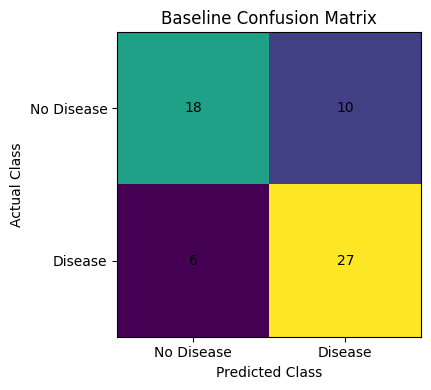

In [5]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Baseline Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0, 1], ["No Disease", "Disease"])
plt.yticks([0, 1], ["No Disease", "Disease"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [6]:
results = X_test.copy()

results["Actual"] = y_test
results["Predicted"] = test_pred
results["Predicted Probability"] = test_prob

results["Error Type"] = np.select(
    [
        (results["Actual"] == 0) & (results["Predicted"] == 1),
        (results["Actual"] == 1) & (results["Predicted"] == 0)
    ],
    [
        "False Positive",
        "False Negative"
    ],
    default="Correct Prediction"
)

false_positives = results[
    results["Error Type"] == "False Positive"
]

false_negatives = results[
    results["Error Type"] == "False Negative"
]

print("False Positive examples:", len(false_positives))
display(false_positives.head(10))

print("False Negative examples:", len(false_negatives))
display(false_negatives.head(10))

False Positive examples: 10


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Predicted Probability,Error Type
194,60,1,2,140,185,0,0,155,0,3.0,1,0,2,0,1,0.62,False Positive
188,50,1,2,140,233,0,1,163,0,0.6,1,1,3,0,1,0.74,False Positive
228,59,1,3,170,288,0,0,159,0,0.2,1,0,3,0,1,0.51,False Positive
267,49,1,2,118,149,0,0,126,0,0.8,2,3,2,0,1,0.74,False Positive
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0,1,0.78,False Positive
281,52,1,0,128,204,1,1,156,1,1.0,1,0,0,0,1,0.54,False Positive
272,67,1,0,120,237,0,1,71,0,1.0,1,0,2,0,1,0.55,False Positive
293,67,1,2,152,212,0,0,150,0,0.8,1,0,3,0,1,0.61,False Positive
286,59,1,3,134,204,0,1,162,0,0.8,2,2,2,0,1,0.86,False Positive
271,61,1,3,134,234,0,1,145,0,2.6,1,2,2,0,1,0.51,False Positive


False Negative examples: 6


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Predicted Probability,Error Type
95,53,1,0,142,226,0,0,111,1,0.0,2,0,3,1,0,0.33,False Negative
107,45,0,0,138,236,0,0,152,1,0.2,1,0,2,1,0,0.44,False Negative
150,66,1,0,160,228,0,0,138,0,2.3,2,0,1,1,0,0.46,False Negative
51,66,1,0,120,302,0,0,151,0,0.4,1,0,2,1,0,0.46,False Negative
70,54,1,2,120,258,0,0,147,0,0.4,1,0,3,1,0,0.46,False Negative
61,54,1,1,108,309,0,1,156,0,0.0,2,0,3,1,0,0.49,False Negative


In [7]:
numeric_features = X_test.select_dtypes(
    include=np.number
).columns.tolist()

fp_data = X_test.loc[false_positives.index]
fn_data = X_test.loc[false_negatives.index]

if len(fp_data) > 0:
    fp_mean = fp_data[numeric_features].mean()
else:
    fp_mean = pd.Series(
        np.nan, index=numeric_features
    )

if len(fn_data) > 0:
    fn_mean = fn_data[numeric_features].mean()
else:
    fn_mean = pd.Series(
        np.nan, index=numeric_features
    )

pattern_table = pd.DataFrame({
    "False Positive Mean": fp_mean,
    "False Negative Mean": fn_mean,
    "Correct Prediction Mean": X_test.loc[
        results["Error Type"] == "Correct Prediction",
        numeric_features
    ].mean()
})

display(pattern_table.round(2))

,False Positive Mean,False Negative Mean,Correct Prediction Mean
age,58.10,56.33,53.78
sex,0.90,0.83,0.60
cp,1.80,0.50,0.98
trestbps,136.60,131.33,131.36
chol,218.20,259.83,262.80
fbs,0.10,0.00,0.22
restecg,0.50,0.17,0.44
thalach,146.10,142.50,148.60
exang,0.10,0.33,0.31
oldpeak,1.08,0.55,0.95


In [8]:
calibrated_model = CalibratedClassifierCV(
    estimator=RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)

cal_valid_prob = calibrated_model.predict_proba(X_valid)[:, 1]
cal_test_prob = calibrated_model.predict_proba(X_test)[:, 1]

print("Calibration completed")
print(
    "Baseline Brier Score:",
    round(brier_score_loss(y_test, test_prob), 4)
)
print(
    "Calibrated Brier Score:",
    round(brier_score_loss(y_test, cal_test_prob), 4)
)

Calibration completed
Baseline Brier Score: 0.1416
Calibrated Brier Score: 0.1402


In [9]:
thresholds = np.arange(0.10, 0.91, 0.05)

f2_scores = []

for threshold in thresholds:
    valid_pred = (
        cal_valid_prob >= threshold
    ).astype(int)

    p = precision_score(
        y_valid, valid_pred, zero_division=0
    )
    r = recall_score(
        y_valid, valid_pred, zero_division=0
    )

    if (4 * p + r) == 0:
        f2 = 0
    else:
        f2 = 5 * p * r / (4 * p + r)

    f2_scores.append(f2)

threshold_results = pd.DataFrame({
    "Threshold": thresholds,
    "Validation F2 Score": f2_scores
})

best_threshold = float(
    threshold_results.loc[
        threshold_results["Validation F2 Score"].idxmax(),
        "Threshold"
    ]
)

display(threshold_results.round(4))

print("Selected threshold:", round(best_threshold, 2))

,Threshold,Validation F2 Score
0,0.10,0.8777
1,0.15,0.8840
2,0.20,0.8989
3,0.25,0.9091
4,0.30,0.8671
5,0.35,0.8671
6,0.40,0.8284
7,0.45,0.8182
8,0.50,0.7975
9,0.55,0.7716


Selected threshold: 0.25


In [10]:
calibrated_default_pred = (
    cal_test_prob >= 0.5
).astype(int)

improved_pred = (
    cal_test_prob >= best_threshold
).astype(int)


def evaluate_model(name, actual, predicted, probabilities):
    cm = confusion_matrix(actual, predicted, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1 Score": f1_score(
            actual, predicted, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "Brier Score": brier_score_loss(
            actual, probabilities
        )
    }


comparison = pd.DataFrame([
    evaluate_model(
        "Baseline (0.5 threshold)",
        y_test, test_pred, test_prob
    ),
    evaluate_model(
        "Calibrated (0.5 threshold)",
        y_test, calibrated_default_pred, cal_test_prob
    ),
    evaluate_model(
        "Calibrated (selected threshold)",
        y_test, improved_pred, cal_test_prob
    )
])

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,False Positives,False Negatives,Brier Score
0,Baseline (0.5 threshold),0.7377,0.7297,0.8182,0.7714,10,6,0.1416
1,Calibrated (0.5 threshold),0.7705,0.7568,0.8485,0.8000,9,5,0.1402
2,Calibrated (selected threshold),0.7213,0.6600,1.0000,0.7952,17,0,0.1402


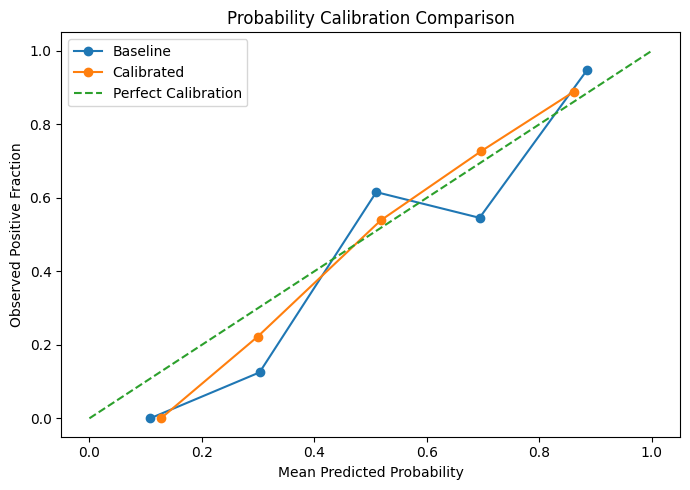

In [11]:
plt.figure(figsize=(7, 5))

for probabilities, label in [
    (test_prob, "Baseline"),
    (cal_test_prob, "Calibrated")
]:
    observed_fraction, mean_probability = calibration_curve(
        y_test,
        probabilities,
        n_bins=5,
        strategy="uniform"
    )

    plt.plot(
        mean_probability,
        observed_fraction,
        marker="o",
        label=label
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Positive Fraction")
plt.title("Probability Calibration Comparison")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
improved_cm = confusion_matrix(
    y_test, improved_pred, labels=[0, 1]
)

tn, fp, fn, tp = improved_cm.ravel()

print("Improved Model Confusion Matrix")
print(improved_cm)
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

improved_results = X_test.copy()
improved_results["Actual"] = y_test
improved_results["Predicted"] = improved_pred
improved_results["Probability"] = cal_test_prob

improved_results["Error Type"] = np.select(
    [
        (improved_results["Actual"] == 0) &
        (improved_results["Predicted"] == 1),

        (improved_results["Actual"] == 1) &
        (improved_results["Predicted"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct Prediction"
)

print("Remaining False Positives")
display(
    improved_results[
        improved_results["Error Type"] == "False Positive"
    ].head(10)
)

print("Remaining False Negatives")
display(
    improved_results[
        improved_results["Error Type"] == "False Negative"
    ].head(10)
)

Improved Model Confusion Matrix
[[11 17]
 [ 0 33]]
True Negatives: 11
False Positives: 17
False Negatives: 0
True Positives: 33
Remaining False Positives


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Probability,Error Type
197,67,1,0,125,254,1,1,163,0,0.2,1,2,3,0,1,0.343992,False Positive
194,60,1,2,140,185,0,0,155,0,3.0,1,0,2,0,1,0.634991,False Positive
188,50,1,2,140,233,0,1,163,0,0.6,1,1,3,0,1,0.709953,False Positive
167,62,0,0,140,268,0,0,160,0,3.6,0,2,2,0,1,0.264100,False Positive
228,59,1,3,170,288,0,0,159,0,0.2,1,0,3,0,1,0.483970,False Positive
267,49,1,2,118,149,0,0,126,0,0.8,2,3,2,0,1,0.638227,False Positive
252,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0,1,0.379406,False Positive
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0,1,0.826319,False Positive
239,35,1,0,126,282,0,0,156,1,0.0,2,0,3,0,1,0.306375,False Positive
264,54,1,0,110,206,0,0,108,1,0.0,1,1,2,0,1,0.293181,False Positive


Remaining False Negatives


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Probability,Error Type


In [13]:
baseline_row = comparison.iloc[0]
calibrated_row = comparison.iloc[1]
improved_row = comparison.iloc[2]

report = f"""
FALSE POSITIVE AND FALSE NEGATIVE ANALYSIS
Heart Disease Classification

1. OBJECTIVE

To investigate misclassified records, identify possible feature
patterns, evaluate probability calibration, and adjust the decision
threshold using validation data.

2. BASELINE MODEL

Accuracy: {baseline_row['Accuracy']:.4f}
Precision: {baseline_row['Precision']:.4f}
Recall: {baseline_row['Recall']:.4f}
F1 Score: {baseline_row['F1 Score']:.4f}
False Positives: {int(baseline_row['False Positives'])}
False Negatives: {int(baseline_row['False Negatives'])}
Brier Score: {baseline_row['Brier Score']:.4f}

3. CALIBRATED MODEL

Accuracy at threshold 0.5: {calibrated_row['Accuracy']:.4f}
Recall at threshold 0.5: {calibrated_row['Recall']:.4f}
False Positives: {int(calibrated_row['False Positives'])}
False Negatives: {int(calibrated_row['False Negatives'])}
Brier Score: {calibrated_row['Brier Score']:.4f}

4. THRESHOLD ADJUSTMENT

Selected threshold: {best_threshold:.2f}
Accuracy: {improved_row['Accuracy']:.4f}
Precision: {improved_row['Precision']:.4f}
Recall: {improved_row['Recall']:.4f}
F1 Score: {improved_row['F1 Score']:.4f}
False Positives: {int(improved_row['False Positives'])}
False Negatives: {int(improved_row['False Negatives'])}
Brier Score: {improved_row['Brier Score']:.4f}

5. INTERPRETATION

False positives are negative cases incorrectly predicted as positive.
False negatives are positive cases incorrectly predicted as negative.

Feature averages from misclassified records can reveal possible
patterns, but they do not establish the cause of model errors.

Probability calibration and threshold adjustment are different:
calibration adjusts probability estimates, while threshold selection
changes the classification decision.

6. LIMITATIONS

Results depend on dataset quality, sample size, feature encoding,
and the selected train-validation-test split. Calibration may not
improve every metric. Threshold selection can trade precision for
recall and requires independent validation.

7. CONCLUSION

The baseline and adjusted models were compared using confusion
matrix counts, precision, recall, F1 score, and Brier score.
The preferred model should be selected based on measured results,
error costs, and additional validation rather than accuracy alone.

This model is for educational analysis and is not validated for
clinical diagnosis or treatment decisions.
"""

with open(
    "Heart_Disease_FP_FN_Analysis_Report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print(report)
print("Report saved successfully.")


FALSE POSITIVE AND FALSE NEGATIVE ANALYSIS
Heart Disease Classification

1. OBJECTIVE

To investigate misclassified records, identify possible feature
patterns, evaluate probability calibration, and adjust the decision
threshold using validation data.

2. BASELINE MODEL

Accuracy: 0.7377
Precision: 0.7297
Recall: 0.8182
F1 Score: 0.7714
False Positives: 10
False Negatives: 6
Brier Score: 0.1416

3. CALIBRATED MODEL

Accuracy at threshold 0.5: 0.7705
Recall at threshold 0.5: 0.8485
False Positives: 9
False Negatives: 5
Brier Score: 0.1402

4. THRESHOLD ADJUSTMENT

Selected threshold: 0.25
Accuracy: 0.7213
Precision: 0.6600
Recall: 1.0000
F1 Score: 0.7952
False Positives: 17
False Negatives: 0
Brier Score: 0.1402

5. INTERPRETATION

False positives are negative cases incorrectly predicted as positive.
False negatives are positive cases incorrectly predicted as negative.

Feature averages from misclassified records can reveal possible
patterns, but they do not establish the cause of mode